# UniqueShip — understand the 72-run overnight sweep

**Dataset:** UniqueShip 5-Class Balanced · **Fold:** 1 · **Features:** 1,206-D pooled STFT · **Selection:** validation macro-F1.

This is an **analysis-only notebook**: it reads CSVs and checkpoint filenames, not audio or `.joblib` model objects. It does **not** retrain models or touch the held-out test partition.

### Using it in VS Code
1. Open your **`UnderwaterVesselDeployment` repository folder** in VS Code.
2. Place this notebook at `notebooks/uniqueship/fold1_sweep_analysis.ipynb` (create the folders if needed).
3. Install the Microsoft **Python** and **Jupyter** extensions if VS Code asks.
4. Click **Select Kernel** at the top right → **Python Environments** → your repository's **`.venv`**. If `matplotlib` or `ipykernel` is missing, install it **in that interpreter** with `python -m pip install matplotlib ipykernel`.
5. Run cells from top to bottom using **Shift+Enter**. Study the displayed tables before advancing.

We will answer: *Did the sweep finish? Which families won? Did bigger MLPs or deeper ensembles help? What is the performance–training-time trade-off? Which checkpoints were saved?*

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

# Use your repo location, never Downloads. VS Code may launch its kernel from
# either the repository root or the notebook directory.
REL = Path("benchmarks/results/uniqueship_stft/fold1_overnight_sweep")
search_starts = [Path.cwd(), Path.home() / "PycharmProjects/UnderwaterVesselDeployment",
                 Path.home() / "Projects/UnderwaterVesselDeployment"]
search_roots = []
for start in search_starts:
    search_roots.extend([start, *start.parents])
REPO_ROOT = next((p for p in search_roots if (p / REL / "sweep_results.csv").is_file()), None)
if REPO_ROOT is None:
    raise FileNotFoundError(
        f"Couldn't find {REL / 'sweep_results.csv'}. Open your repository in VS Code, "
        "or set REPO_ROOT = Path('/absolute/path/to/UnderwaterVesselDeployment') here.")
SWEEP_DIR = REPO_ROOT / REL
RESULTS_CSV = SWEEP_DIR / "sweep_results.csv"
LEADERBOARD_CSV = SWEEP_DIR / "leaderboard.csv"
PLAN_JSON = SWEEP_DIR / "sweep_plan.json"
print("Repository:", REPO_ROOT)
print("Sweep data:", SWEEP_DIR)
print("Result files:", [p.name for p in (RESULTS_CSV, LEADERBOARD_CSV, PLAN_JSON) if p.exists()])

Repository: /Users/abisheksoti/PycharmProjects/UnderwaterVesselDeployment
Sweep data: /Users/abisheksoti/PycharmProjects/UnderwaterVesselDeployment/benchmarks/results/uniqueship_stft/fold1_overnight_sweep
Result files: ['sweep_results.csv', 'leaderboard.csv', 'sweep_plan.json']


## 1. Load the raw experimental record

The sweep writes **one row per configuration**. Important columns: `family`, `params` (JSON), `status`, `validation_macro_f1`, `validation_accuracy`, and `fit_seconds`.

Check for missing values, duplicates, failed configurations and the expected **72 distinct IDs** before trusting any winner.

In [2]:
df = pd.read_csv(RESULTS_CSV)
required = {"id", "family", "status", "params", "validation_macro_f1",
            "validation_accuracy", "fit_seconds"}
missing_cols = required - set(df.columns)
if missing_cols:
    raise ValueError(f"CSV missing required columns: {sorted(missing_cols)}")
for column in ("validation_macro_f1", "validation_accuracy", "fit_seconds", "validation_seconds"):
    if column in df.columns:
        df[column] = pd.to_numeric(df[column], errors="coerce")

plan = json.loads(PLAN_JSON.read_text()) if PLAN_JSON.exists() else None
planned = len(plan["candidates"]) if plan else 72
print(f"Rows: {len(df)} | Unique configurations: {df['id'].nunique()} | Planned: {planned}")
print("Status counts:\n", df["status"].value_counts(dropna=False).to_string())
print("Runs by family and status:")
display(pd.crosstab(df["family"], df["status"]))

if df["id"].duplicated().any():
    print("WARNING: duplicate config IDs:")
    display(df[df["id"].duplicated(keep=False)][["id", "family", "status"]])
if plan:
    expected = {item["id"] for item in plan["candidates"]}
    actual = set(df["id"])
    print(f"Planned runs missing from results: {len(expected - actual)}")
    print(f"Unexpected runs not in plan: {len(actual - expected)}")

ok = df.loc[df["status"].eq("ok")].dropna(subset=["validation_macro_f1", "fit_seconds"]).copy()
failures = df.loc[df["status"].ne("ok")].copy()
if not failures.empty:
    display(failures[[c for c in ["family", "id", "error"] if c in failures.columns]])
if ok.empty:
    raise RuntimeError("No successful sweep fits are present; inspect overnight_sweep.log")
print(f"Successful evaluated fits: {len(ok)}/{planned}")

Rows: 72 | Unique configurations: 72 | Planned: 72
Status counts:
 status
ok    72
Runs by family and status:


status,ok
family,
extratrees,10
histgb,24
mlp,30
randomforest,8


Planned runs missing from results: 0
Unexpected runs not in plan: 0
Successful evaluated fits: 72/72


## 2. What do accuracy and macro-F1 measure?

- **Accuracy:** fraction of all validation clips classified correctly. It is sensitive to class frequency.
- **Macro-F1:** calculate the F1 score for *each* vessel class and then average the five values equally. This is our sweep's model-selection metric.
- Values in the CSV are between 0 and 1. We multiply by 100 for readable percentages.

**Research discipline:** don't use the test set to choose hyperparameters. These analyses are entirely validation-based.

In [3]:
view = ok.copy()
view["Val macro-F1 (%)"] = view["validation_macro_f1"] * 100
view["Val accuracy (%)"] = view["validation_accuracy"] * 100
view["Fit time (s)"] = view["fit_seconds"]
columns = ["family", "Val macro-F1 (%)", "Val accuracy (%)", "Fit time (s)", "params", "id"]
print("Top 12 configurations by validation macro-F1:")
display(view.sort_values(["validation_macro_f1", "validation_accuracy"], ascending=False)[columns].head(12))
print("Absolute winner:")
champion = view.sort_values("validation_macro_f1", ascending=False).iloc[0]
print(f"  {champion['family']} | macro-F1={champion['Val macro-F1 (%)']:.2f}% "
      f"| accuracy={champion['Val accuracy (%)']:.2f}% | fit={champion['Fit time (s)']:.1f}s")
print("  Hyperparameters:", json.loads(champion["params"]))

Top 12 configurations by validation macro-F1:


,family,Val macro-F1 (%),Val accuracy (%),Fit time (s),params,id
13,histgb,62.9313,64.7733,229.7810,"{""l2_regularization"":1.0,""learning_rate"":0.04,""max_iter"":450,""max_leaf_nodes"":15,""min_samples_leaf"":20}",histgb_c5d759e52b0e
36,histgb,62.9246,64.6749,311.3880,"{""l2_regularization"":1.0,""learning_rate"":0.04,""max_iter"":450,""max_leaf_nodes"":31,""min_samples_leaf"":20}",histgb_6e2cf3bb76da
59,histgb,62.9217,64.7381,216.4990,"{""l2_regularization"":0.1,""learning_rate"":0.04,""max_iter"":300,""max_leaf_nodes"":31,""min_samples_leaf"":20}",histgb_ab259a6632f8
51,histgb,62.9129,64.7803,149.1890,"{""l2_regularization"":0.1,""learning_rate"":0.08,""max_iter"":300,""max_leaf_nodes"":15,""min_samples_leaf"":20}",histgb_4fda2442267c
63,histgb,62.7514,64.5413,221.4340,"{""l2_regularization"":1.0,""learning_rate"":0.04,""max_iter"":300,""max_leaf_nodes"":31,""min_samples_leaf"":20}",histgb_91ed54931487
65,histgb,62.7056,64.4991,151.0020,"{""l2_regularization"":1.0,""learning_rate"":0.08,""max_iter"":300,""max_leaf_nodes"":15,""min_samples_leaf"":20}",histgb_e025f7f930da
33,histgb,62.6903,64.4710,300.8880,"{""l2_regularization"":1.0,""learning_rate"":0.08,""max_iter"":300,""max_leaf_nodes"":63,""min_samples_leaf"":20}",histgb_d5f5e345add9
21,histgb,62.5273,64.4359,161.6040,"{""l2_regularization"":1.0,""learning_rate"":0.04,""max_iter"":300,""max_leaf_nodes"":15,""min_samples_leaf"":20}",histgb_999696e7b137
5,histgb,62.5014,64.1968,143.2810,"{""l2_regularization"":0.1,""learning_rate"":0.12,""max_iter"":300,""max_leaf_nodes"":15,""min_samples_leaf"":20}",histgb_e3966a36c235
39,histgb,62.4948,64.2390,114.0370,"{""l2_regularization"":1.0,""learning_rate"":0.08,""max_iter"":150,""max_leaf_nodes"":31,""min_samples_leaf"":20}",histgb_891405e4e645


Absolute winner:
  histgb | macro-F1=62.93% | accuracy=64.77% | fit=229.8s
  Hyperparameters: {'l2_regularization': 1.0, 'learning_rate': 0.04, 'max_iter': 450, 'max_leaf_nodes': 15, 'min_samples_leaf': 20}


## 3. Compare the sweep with the original four models

We already have fixed-split **validation** baselines. The original Logistic Regression was the overall best at **63.02% macro-F1**; the original MLP was at **57.55%**. 

Compare *family to family* as well as *best overall*. Note that the sweep did not train new Logistic Regression or RBF-SVM models.

In [4]:
baseline = pd.DataFrame([
    {"model": "Logistic Regression", "family": "logreg", "macro_f1": 0.630215, "accuracy": 0.644359},
    {"model": "Approx. RBF-SVM", "family": "rbf_svm", "macro_f1": 0.602047, "accuracy": 0.620949},
    {"model": "Original MLP (128,64)", "family": "mlp", "macro_f1": 0.575535, "accuracy": 0.597540},
    {"model": "Original HistGB", "family": "histgb", "macro_f1": 0.621332, "accuracy": 0.640492},
])
family_best = ok.sort_values("validation_macro_f1", ascending=False).drop_duplicates("family").copy()
family_best["macro_F1_%"] = 100 * family_best["validation_macro_f1"]
family_best["accuracy_%"] = 100 * family_best["validation_accuracy"]
comparison = family_best[["family", "macro_F1_%", "accuracy_%", "fit_seconds", "params", "id"]].copy()
comparison = comparison.merge(baseline[["family", "macro_f1"]], on="family", how="left")
comparison["change_vs_original_pp"] = comparison["macro_F1_%"] - 100*comparison["macro_f1"]
comparison["difference_vs_best_original_pp"] = comparison["macro_F1_%"] - 100*baseline["macro_f1"].max()
print("Best sweep configuration by family (pp = percentage points):")
display(comparison.sort_values("macro_F1_%", ascending=False))
print(f"Top original validation macro-F1: {baseline['macro_f1'].max():.2%}")
print("Positive change_vs_original_pp means a family improved over its original model.")

Best sweep configuration by family (pp = percentage points):


,family,macro_F1_%,accuracy_%,fit_seconds,params,id,macro_f1,change_vs_original_pp,difference_vs_best_original_pp
0,histgb,62.9313,64.7733,229.7810,"{""l2_regularization"":1.0,""learning_rate"":0.04,""max_iter"":450,""max_leaf_nodes"":15,""min_samples_leaf"":20}",histgb_c5d759e52b0e,0.6213,0.7981,-0.0902
1,mlp,61.9588,64.3585,164.0860,"{""alpha"":0.0001,""batch_size"":512,""hidden_layer_sizes"":[512,256],""learning_rate_init"":0.0003,""max_iter"":220}",mlp_c678827056e2,0.5755,4.4053,-1.0627
2,randomforest,59.5658,62.2004,"3,079.1080","{""max_features"":0.3,""max_leaf_nodes"":127,""min_samples_leaf"":5,""n_estimators"":400}",randomforest_08aff52fa177,NaN,NaN,-3.4557
3,extratrees,58.4901,61.0404,342.7780,"{""max_features"":0.3,""max_leaf_nodes"":127,""min_samples_leaf"":5,""n_estimators"":300}",extratrees_01cfb7fe790b,NaN,NaN,-4.5314


Top original validation macro-F1: 63.02%
Positive change_vs_original_pp means a family improved over its original model.


## 4. Did 72 configurations provide consistent gains, or just one lucky result?

For each family, look at the **best**, **median** and **worst** validation F1. The median is useful because the very best configuration can hide dozens of weaker runs.

A single Fold 1 sweep is *not* a confidence interval; the runs share training/validation data and were selected adaptively.

,runs,Best F1 (%),Median F1 (%),Worst F1 (%),Median fit (s),total_fit_hours
family,,,,,,
histgb,24,62.9313,62.3557,61.7978,211.6425,1.7695
mlp,30,61.9588,59.4528,56.9739,166.5890,1.6715
randomforest,8,59.5658,58.3667,56.6115,"1,445.0845",3.0278
extratrees,10,58.4901,52.9860,51.6789,66.2420,0.5523


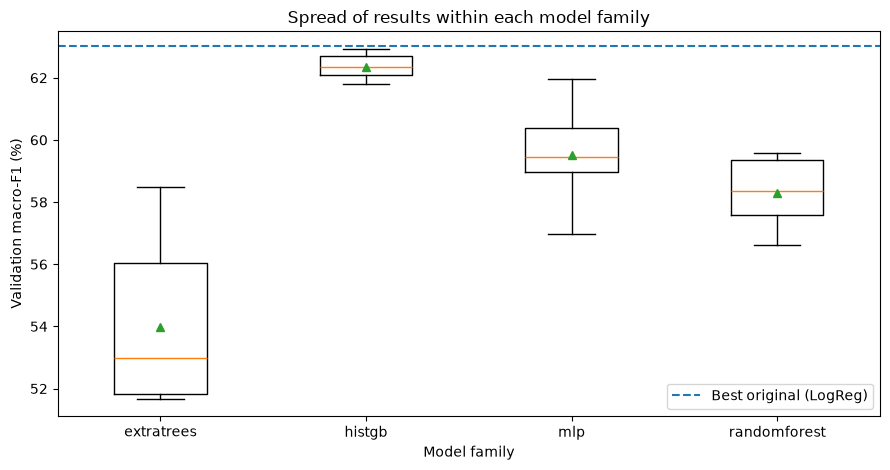

In [5]:
overview = ok.groupby("family").agg(
    runs=("id", "nunique"),
    best_macro_f1=("validation_macro_f1", "max"),
    median_macro_f1=("validation_macro_f1", "median"),
    worst_macro_f1=("validation_macro_f1", "min"),
    median_fit_s=("fit_seconds", "median"),
    total_fit_hours=("fit_seconds", lambda s: s.sum()/3600),
).sort_values("best_macro_f1", ascending=False)
for col in ["best_macro_f1", "median_macro_f1", "worst_macro_f1"]:
    overview[col] *= 100
display(overview.rename(columns={"best_macro_f1":"Best F1 (%)", "median_macro_f1":"Median F1 (%)",
                                 "worst_macro_f1":"Worst F1 (%)", "median_fit_s":"Median fit (s)"}))
fig, ax = plt.subplots(figsize=(9,4.8))
families = sorted(ok["family"].unique())
vals = [ok.loc[ok.family.eq(f), "validation_macro_f1"].dropna().to_numpy()*100 for f in families]
ax.boxplot(vals, tick_labels=families, showmeans=True)
ax.axhline(baseline["macro_f1"].max()*100, linestyle="--", label="Best original (LogReg)")
ax.set(xlabel="Model family", ylabel="Validation macro-F1 (%)", title="Spread of results within each model family")
ax.legend()
plt.tight_layout(); plt.show()

## 5. Separate model quality from training cost

A good classification model for *embedded deployment* must also be compact and efficient. Here we compare **fit time** (training on your Mac) against validation macro-F1. **This does not measure Raspberry Pi inference time or memory.**

Ask: *Does a much slower training configuration yield a worthwhile macro-F1 gain?*

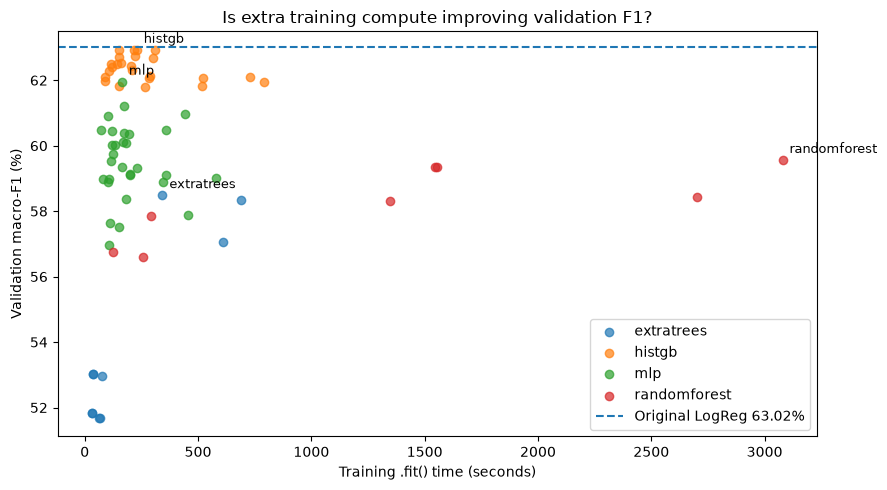

In [6]:
fig, ax = plt.subplots(figsize=(9,5))
for family, grp in ok.groupby("family"):
    ax.scatter(grp["fit_seconds"], grp["validation_macro_f1"]*100, label=family, alpha=0.7)
for _, row in family_best.iterrows():
    ax.annotate(row["family"], (row["fit_seconds"], 100*row["validation_macro_f1"]),
                xytext=(5,5), textcoords="offset points", fontsize=9)
ax.axhline(100*baseline["macro_f1"].max(), linestyle="--", label="Original LogReg 63.02%")
ax.set(xlabel="Training .fit() time (seconds)", ylabel="Validation macro-F1 (%)",
       title="Is extra training compute improving validation F1?")
ax.legend(); plt.tight_layout(); plt.show()

## 6. Decode the JSON hyperparameters

Each `params` cell is a JSON dictionary such as `{"hidden_layer_sizes":[512,256], "alpha":0.0001, ...}`. Convert it into real columns so you can group and plot them. Different families have different parameter names.

**Do not interpret these one-at-a-time comparisons as causal ablation studies:** the random shortlist didn't necessarily hold every other parameter constant.

In [8]:
decoded = pd.json_normalize(ok["params"].apply(json.loads))
params_df = pd.concat([ok.reset_index(drop=True).drop(columns=["params"]),
                       decoded.reset_index(drop=True)], axis=1)
print("Families and parameter fields:")
for family, group in params_df.groupby("family"):
    fields = [c for c in decoded.columns if group[c].notna().any()]
    print(f"  {family}: {', '.join(fields)}")
print("Example fully decoded rows:")
display(params_df.head(6))

Families and parameter fields:
  extratrees: max_leaf_nodes, min_samples_leaf, max_features, n_estimators
  histgb: max_iter, l2_regularization, learning_rate, max_leaf_nodes, min_samples_leaf
  mlp: alpha, batch_size, hidden_layer_sizes, learning_rate_init, max_iter
  randomforest: max_leaf_nodes, min_samples_leaf, max_features, n_estimators
Example fully decoded rows:


,id,family,status,validation_macro_f1,validation_accuracy,fit_seconds,validation_seconds,train_n,validation_n,started_at,error,alpha,batch_size,hidden_layer_sizes,learning_rate_init,max_iter,l2_regularization,learning_rate,max_leaf_nodes,min_samples_leaf,max_features,n_estimators
0,mlp_d1c69a83ed0d,mlp,ok,0.5931,0.6146,232.0670,0.1700,125088,14225,2026-10-27T02:13:28+11:00,NaN,0.0001,256.0000,"[512, 256, 128]",0.0010,220.0000,NaN,NaN,NaN,NaN,NaN,NaN
1,histgb_cd3db0370a64,histgb,ok,0.6212,0.6395,288.3570,1.2700,125088,14225,2026-10-27T02:17:23+11:00,NaN,NaN,NaN,NaN,NaN,150.0000,1.0000,0.0800,127.0000,20.0000,NaN,NaN
2,extratrees_bc39558887a5,extratrees,ok,0.5168,0.5394,67.6500,0.2110,125088,14225,2026-10-27T02:22:13+11:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,63.0000,2.0000,sqrt,600.0000
3,randomforest_dca0a772045d,randomforest,ok,0.5935,0.6200,"1,554.9350",0.1590,125088,14225,2026-10-27T02:23:21+11:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,127.0000,5.0000,0.3000,200.0000
4,mlp_8da005c60ef8,mlp,ok,0.6048,0.6245,71.6070,0.1750,125088,14225,2026-10-27T02:49:16+11:00,NaN,0.0100,512.0000,"[256, 128, 64]",0.0010,220.0000,NaN,NaN,NaN,NaN,NaN,NaN
5,histgb_e3966a36c235,histgb,ok,0.6250,0.6420,143.2810,0.6530,125088,14225,2026-10-27T02:50:28+11:00,NaN,NaN,NaN,NaN,NaN,300.0000,0.1000,0.1200,15.0000,20.0000,NaN,NaN


## 7. Did a larger MLP actually help?

We calculate the **exact dense trainable weights + biases** from the architecture assuming 1,206 input features and 5 outputs. For example, the original `(128,64)` MLP has 163,077 parameters. This count excludes preprocessing scaler statistics.

**Interpretation:** capacity may improve the fit, but too many parameters may also overfit. Your sweep stores no training F1, so we cannot diagnose overfitting using these files alone.

,architecture,param_count,runs,best_f1,median_f1,median_fit_s
1,256-128,342533,6,60.9037,59.4968,108.7800
2,256-128-64,350469,6,60.4771,59.6440,117.1155
3,512-256,750597,6,61.9588,60.1003,166.5890
4,512-256-128,782853,5,60.3587,59.1498,198.1080
0,1024-512-256,1893381,7,60.9587,59.1190,358.7430


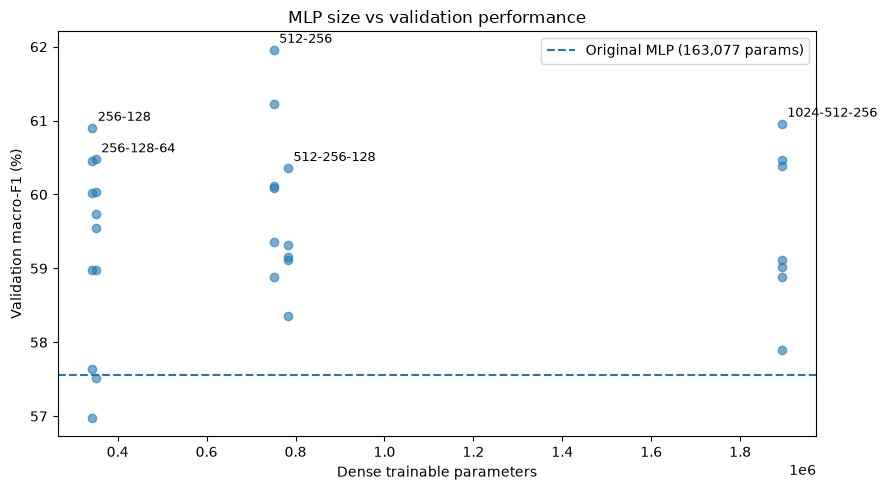

In [9]:
def dense_params(hidden, input_dim=1206, classes=5):
    sizes = [input_dim, *[int(x) for x in hidden], classes]
    return sum(a*b + b for a,b in zip(sizes[:-1], sizes[1:]))

mlp = params_df.loc[params_df["family"].eq("mlp")].copy()
if mlp.empty:
    print("No MLP sweep rows to analyse")
else:
    mlp["architecture"] = mlp["hidden_layer_sizes"].apply(lambda a: "-".join(str(x) for x in a))
    mlp["param_count"] = mlp["hidden_layer_sizes"].apply(dense_params)
    summary = mlp.groupby(["architecture", "param_count"]).agg(
        runs=("id", "count"), best_f1=("validation_macro_f1", "max"),
        median_f1=("validation_macro_f1", "median"), median_fit_s=("fit_seconds", "median")
    ).reset_index().sort_values("param_count")
    summary[["best_f1", "median_f1"]] *= 100
    display(summary)
    fig, ax = plt.subplots(figsize=(9,5))
    ax.scatter(mlp["param_count"], mlp["validation_macro_f1"]*100, alpha=.6)
    for _, r in summary.iterrows():
        ax.annotate(r["architecture"], (r["param_count"], r["best_f1"]),
                    xytext=(4,5), textcoords="offset points", fontsize=9)
    ax.axhline(baseline.loc[baseline.family.eq("mlp"), "macro_f1"].iloc[0]*100,
               linestyle="--", label="Original MLP (163,077 params)")
    ax.set(xlabel="Dense trainable parameters", ylabel="Validation macro-F1 (%)",
           title="MLP size vs validation performance")
    ax.legend(); plt.tight_layout(); plt.show()

## 8. What about MLP regularisation, batch size and learning rate?

- `alpha` (L2): discourages large weights.
- `learning_rate_init`: initial Adam update size.
- `batch_size`: clips per minibatch.

Compare their **best** and **median** values with run counts. Since the sweep sampled only 30 MLP configurations, other parameters vary simultaneously; these are exploratory trends, not isolated effects.

In [10]:
if not mlp.empty:
    for param in ["alpha", "learning_rate_init", "batch_size"]:
        tbl = mlp.groupby(param, dropna=False)["validation_macro_f1"].agg(["size", "max", "median"])
        tbl[["max", "median"]] *= 100
        print(f"\nMLP parameter: {param}  (values are macro-F1 percentages)")
        display(tbl.rename(columns={"size":"runs", "max":"best_F1_%", "median":"median_F1_%"}))


MLP parameter: alpha  (values are macro-F1 percentages)


,runs,best_F1_%,median_F1_%
alpha,,,
0.0001,8,61.9588,60.0562
0.0010,10,61.2227,59.4528
0.0100,12,60.4771,59.0675



MLP parameter: learning_rate_init  (values are macro-F1 percentages)


,runs,best_F1_%,median_F1_%
learning_rate_init,,,
0.0003,16,61.9588,60.0633
0.0010,14,60.9037,58.9980



MLP parameter: batch_size  (values are macro-F1 percentages)


,runs,best_F1_%,median_F1_%
batch_size,,,
256.0000,15,60.9587,59.3110
512.0000,15,61.9588,60.1084


## 9. Does HistGradientBoosting benefit from more iterations and leaves?

For multiclass HistGB, a *boosting round* adds one tree per class (five here). So 300 rounds is about 1,500 class-specific trees, subject to the fitting rules—not 300 trees total. `max_leaf_nodes` limits the complexity **of each tree**.

Look for a plateau: similar validation F1 with many fewer rounds/leaves may be a better deployment candidate.

Top 8 HistGB configurations:


,validation_macro_f1,validation_accuracy,fit_seconds,max_iter,max_leaf_nodes,learning_rate,l2_regularization,min_samples_leaf
13,0.6293,0.6477,229.7810,450.0000,15.0000,0.0400,1.0000,20.0000
36,0.6292,0.6467,311.3880,450.0000,31.0000,0.0400,1.0000,20.0000
59,0.6292,0.6474,216.4990,300.0000,31.0000,0.0400,0.1000,20.0000
51,0.6291,0.6478,149.1890,300.0000,15.0000,0.0800,0.1000,20.0000
63,0.6275,0.6454,221.4340,300.0000,31.0000,0.0400,1.0000,20.0000
65,0.6271,0.6450,151.0020,300.0000,15.0000,0.0800,1.0000,20.0000
33,0.6269,0.6447,300.8880,300.0000,63.0000,0.0800,1.0000,20.0000
21,0.6253,0.6444,161.6040,300.0000,15.0000,0.0400,1.0000,20.0000


Best validation macro-F1 (%) for each observed rounds × leaves combination:


max_leaf_nodes,15.0000,31.0000,63.0000,127.0000
max_iter,,,,
150.0000,62.0901,62.4948,61.8245,62.1196
300.0000,62.9129,62.9217,62.6903,62.0671
450.0000,62.9313,62.9246,NaN,62.1048


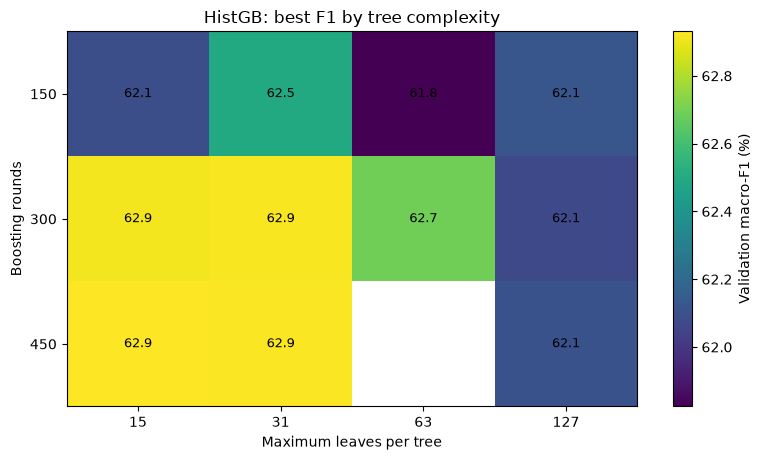

In [11]:
hist = params_df.loc[params_df.family.eq("histgb")].copy()
if not hist.empty:
    print("Top 8 HistGB configurations:")
    display(hist.sort_values("validation_macro_f1", ascending=False)[[
        "validation_macro_f1", "validation_accuracy", "fit_seconds", "max_iter", "max_leaf_nodes",
        "learning_rate", "l2_regularization", "min_samples_leaf"]].head(8))
    g = hist.groupby(["max_iter", "max_leaf_nodes"])["validation_macro_f1"].agg(["max", "count"])
    pivot = (100 * g["max"]).unstack("max_leaf_nodes")
    print("Best validation macro-F1 (%) for each observed rounds × leaves combination:")
    display(pivot)
    fig, ax = plt.subplots(figsize=(8,4.7))
    im = ax.imshow(pivot.to_numpy(dtype=float), aspect="auto", interpolation="nearest")
    ax.set_xticks(np.arange(len(pivot.columns)), labels=[str(int(v)) for v in pivot.columns])
    ax.set_yticks(np.arange(len(pivot.index)), labels=[str(int(v)) for v in pivot.index])
    ax.set(xlabel="Maximum leaves per tree", ylabel="Boosting rounds", title="HistGB: best F1 by tree complexity")
    for i in range(len(pivot.index)):
        for j in range(len(pivot.columns)):
            value = pivot.iloc[i,j]
            if pd.notna(value):
                ax.text(j, i, f"{value:.1f}", ha="center", va="center", fontsize=9)
    fig.colorbar(im, ax=ax, label="Validation macro-F1 (%)")
    plt.tight_layout(); plt.show()
else:
    print("No successful HistGB runs")

## 10. Compare Extra Trees and Random Forest

Both use collections of decision trees, but **Extra Trees randomises thresholds more aggressively**, while **Random Forest generally searches for stronger splits in bootstrap samples**. The sweep varies tree count, leaf limit, feature sampling and minimum samples per leaf.

Don't assume more trees automatically means better accuracy. Increasing tree count generally increases storage and inference cost.

Best 5 Extra Trees / Random Forest configurations each:

extratrees:


,validation_macro_f1,validation_accuracy,fit_seconds,n_estimators,max_leaf_nodes,max_features,min_samples_leaf
18,0.5849,0.6104,342.7780,300.0000,127.0000,0.3000,5.0000
26,0.5835,0.6091,688.5560,600.0000,127.0000,0.3000,5.0000
30,0.5705,0.5962,609.6510,600.0000,63.0000,0.3000,5.0000
10,0.5302,0.5551,37.0420,300.0000,127.0000,sqrt,5.0000
22,0.5302,0.5551,37.5250,300.0000,127.0000,sqrt,2.0000



randomforest:


,validation_macro_f1,validation_accuracy,fit_seconds,n_estimators,max_leaf_nodes,max_features,min_samples_leaf
27,0.5957,0.6220,"3,079.1080",400.0000,127.0000,0.3000,5.0000
3,0.5935,0.6200,"1,554.9350",200.0000,127.0000,0.3000,5.0000
19,0.5935,0.6200,"1,544.1640",200.0000,127.0000,0.3000,2.0000
31,0.5842,0.6112,"2,699.6160",400.0000,63.0000,0.3000,5.0000
11,0.5832,0.6101,"1,346.0050",200.0000,63.0000,0.3000,2.0000


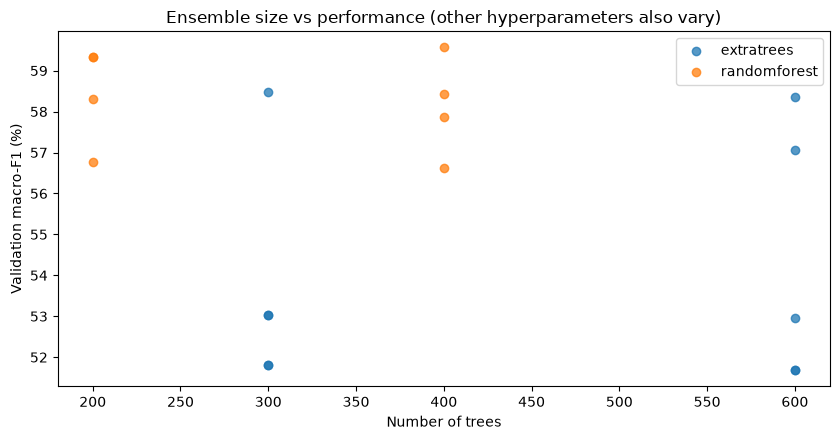

In [12]:
trees = params_df[params_df.family.isin(["extratrees", "randomforest"])].copy()
if not trees.empty:
    print("Best 5 Extra Trees / Random Forest configurations each:")
    for family, group in trees.groupby("family"):
        print(f"\n{family}:")
        display(group.sort_values("validation_macro_f1", ascending=False)[[
            "validation_macro_f1", "validation_accuracy", "fit_seconds", "n_estimators",
            "max_leaf_nodes", "max_features", "min_samples_leaf"]].head(5))
    fig, ax = plt.subplots(figsize=(8.5,4.5))
    for family, grp in trees.groupby("family"):
        ax.scatter(grp["n_estimators"], 100*grp["validation_macro_f1"], label=family, alpha=0.75)
    ax.set(xlabel="Number of trees", ylabel="Validation macro-F1 (%)",
           title="Ensemble size vs performance (other hyperparameters also vary)")
    ax.legend(); plt.tight_layout(); plt.show()
else:
    print("No tree-ensemble sweep rows")

## 11. Which fitted checkpoints actually exist?

The sweep intentionally saved **only one best `.joblib` checkpoint per family** (not all 72 models). We inspect file presence and byte size; **do not load model objects in this analysis**.

File size is a useful deployment consideration. It isn't directly interchangeable with parameter count, especially for trees.

In [ ]:
if plan and "dataset_root" in plan:
    dataset_root = Path(plan["dataset_root"])
    artifact_dir = dataset_root.parent.parent / "model_artifacts/stft_axis_stats_v1/sweeps"
else:
    artifact_dir = Path.home() / "Local Documents/Datasets/UniqueShip/5class_balanced/model_artifacts/stft_axis_stats_v1/sweeps"
files = []
for family in sorted(ok.family.unique()):
    p = artifact_dir / f"fold1_{family}_sweep_best.joblib"
    files.append({"family":family, "exists":p.is_file(),
                  "size_MiB":round(p.stat().st_size/(1024**2), 3) if p.is_file() else np.nan,
                  "file":str(p)})
print("Model directory:", artifact_dir)
display(pd.DataFrame(files))
print("Saved checkpoint = best VALIDATION-F1 model per family, not necessarily the test winner.")

## 12. Export a clean research summary — without modifying original results

This cell writes **two new small CSVs** next to your existing sweep results. It doesn't overwrite `sweep_results.csv`, `leaderboard.csv` or any model.

**Publication note:** the previous held-out test performance was for the *original* four configurations. Any new test evaluation of selected sweep winners needs to be marked as post-validation tuning; don't report the 72-way winner's test score as though it was selected before looking at any test results.

In [ ]:
export_cols = ["family", "id", "validation_macro_f1", "validation_accuracy", "fit_seconds", "params"]
family_winners = ok.sort_values("validation_macro_f1", ascending=False).drop_duplicates("family")[export_cols]
top_12 = ok.sort_values("validation_macro_f1", ascending=False).head(12)[export_cols]
family_path = SWEEP_DIR / "analysis_family_winners.csv"
top_path = SWEEP_DIR / "analysis_top12.csv"
family_winners.to_csv(family_path, index=False)
top_12.to_csv(top_path, index=False)
print("Wrote:", family_path.name, "and", top_path.name)
print("Recommended interpretation:")
best = family_winners.iloc[0]
delta_pp = 100 * (best["validation_macro_f1"] - baseline["macro_f1"].max())
print(f"  Best sweep family = {best['family']}, validation macro-F1 = {best['validation_macro_f1']:.2%}")
print(f"  Difference against best original LogReg = {delta_pp:+.2f} percentage points")
print("  These are ONE FOLD'S validation results, NOT test means ± SD across five splits.")

## Questions to think about before the next experiment

1. Which **model family** has the highest validation macro-F1, and by how many *percentage points* does it beat (or trail) the original Logistic Regression?
2. Does the largest MLP outperform the smaller architectures **consistently**, or are its scores variable? Could the extra parameters be fitting noise?
3. Are 450 boosting rounds and 127 leaves meaningfully better than smaller HistGB models? Consider both F1 and fitting time.
4. Which ensemble looks promising for a Raspberry Pi, where **serialized size, end-to-end latency and RAM** matter more than Mac training time?
5. Before publication, how will we address the **background-day overlap warnings** in the supplied UniqueShip Fold 1 partitions?

**Next phase (separate experiment):** use your saved best-family checkpoints to create per-class confusion matrices and probability reliability plots on *validation*. Reserve held-out test evaluation for the final, explicitly reported comparison.